In [1]:
!pip install opendatasets --upgrade --quiet
import opendatasets as od


In [2]:
dataset_link = "https://www.kaggle.com/datasets/azminur2856/alzheimer-mri-dataset"
od.download(dataset_link)


Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: zaman363
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/azminur2856/alzheimer-mri-dataset


100%|██████████| 373M/373M [00:04<00:00, 78.1MB/s]


In [3]:
dataset_link = "https://www.kaggle.com/datasets/aryansinghal10/alzheimers-multiclass-dataset-equal-and-augmented"
od.download(dataset_link)


Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: zaman363
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/aryansinghal10/alzheimers-multiclass-dataset-equal-and-augmented


100%|██████████| 398M/398M [00:06<00:00, 64.0MB/s]


## Step 1: Clear Session & Release Memory

In [4]:
!pip install tensorflow --quiet
import tensorflow as tf
import gc

tf.keras.backend.clear_session()
gc.collect()
print('Session cleared. Memory released.')

Session cleared. Memory released.


## Step 2: Import Libraries

In [5]:
import os
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageEnhance
from sklearn.utils import shuffle
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

from tensorflow.keras.applications import Xception
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

sns.set_style('darkgrid')
print('All libraries imported successfully.')

All libraries imported successfully.


## Step 3: Configuration

> **Update ONLY this cell to adapt to any dataset.**
> The rest of the notebook runs automatically.

In [6]:
# ============================================================
#  CONFIGURATION — Edit these values for your dataset
# ============================================================

TRAIN_DIR_1 = '/content/alzheimer-mri-dataset/Data'

TRAIN_DIR_2 = '/content/alzheimers-multiclass-dataset-equal-and-augmented/combined_images'

IMAGE_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 20
LEARNING_RATE = 0.0001

# How many of the last layers to unfreeze
UNFREEZE_LAST_N_LAYERS = 0

# Train / Validation / Test split
TRAIN_SPLIT = 0.80
VAL_SPLIT = 0.10
# Remaining becomes test set

MODEL_SAVE_PATH = 'Xception_Baseline model.keras'

# ============================================================

print(f'Training dir 1 : {TRAIN_DIR_1}')
print(f'Training dir 2 : {TRAIN_DIR_2}')
print(f'Image size     : {IMAGE_SIZE}x{IMAGE_SIZE}')
print(f'Batch size     : {BATCH_SIZE} | Epochs: {EPOCHS}')

Training dir 1 : /content/alzheimer-mri-dataset/Data
Training dir 2 : /content/alzheimers-multiclass-dataset-equal-and-augmented/combined_images
Image size     : 224x224
Batch size     : 16 | Epochs: 20


## Step 4: Load Dataset

Automatically reads class folders, collects image paths, and assigns labels.

In [7]:
def load_paths_and_labels(directory):
    """Walk a directory tree and return (paths, labels) lists."""
    paths, labels = [], []

    for label in sorted(os.listdir(directory)):
        label_dir = os.path.join(directory, label)

        if not os.path.isdir(label_dir):
            continue

        for fname in os.listdir(label_dir):
            fpath = os.path.join(label_dir, fname)

            if fname.lower().endswith(
                ('.jpg', '.jpeg', '.png', '.bmp', '.tiff')
            ):
                paths.append(fpath)
                labels.append(label)

    return shuffle(paths, labels, random_state=42)


# Load training (merged) data

train_paths_1, train_labels_1 = load_paths_and_labels(TRAIN_DIR_1)

train_paths_2, train_labels_2 = load_paths_and_labels(TRAIN_DIR_2)

train_paths = train_paths_1 + train_paths_2

train_labels = train_labels_1 + train_labels_2

train_paths, train_labels = shuffle(
    train_paths,
    train_labels,
    random_state=42
)

CLASS_NAMES = sorted(os.listdir(TRAIN_DIR_1))
NUM_CLASSES = len(CLASS_NAMES)

print(f'Classes ({NUM_CLASSES}): {CLASS_NAMES}')
print(f'Total training images: {len(train_paths)}')


# Auto-split train → train / val / test

n = len(train_paths)

train_end = int(n * TRAIN_SPLIT)

val_end = train_end + int(n * VAL_SPLIT)

val_paths, val_labels = (
    train_paths[train_end:val_end],
    train_labels[train_end:val_end]
)

test_paths, test_labels = (
    train_paths[val_end:],
    train_labels[val_end:]
)

train_paths, train_labels = (
    train_paths[:train_end],
    train_labels[:train_end]
)

print(
    f'Split → Train: {len(train_paths)} | '
    f'Val: {len(val_paths)} | '
    f'Test: {len(test_paths)}'
)


# Class distribution

from collections import Counter

dist = Counter(train_labels)

print('\nClass distribution (train):')

for cls, cnt in sorted(dist.items()):
    print(f'  {cls:30s}: {cnt}')

Classes (4): ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']
Total training images: 84000
Split → Train: 67200 | Val: 8400 | Test: 8400

Class distribution (train):
  MildDemented                  : 15930
  ModerateDemented              : 15991
  NonDemented                   : 18217
  VeryMildDemented              : 17062


## Step 5: Visualize Sample Images

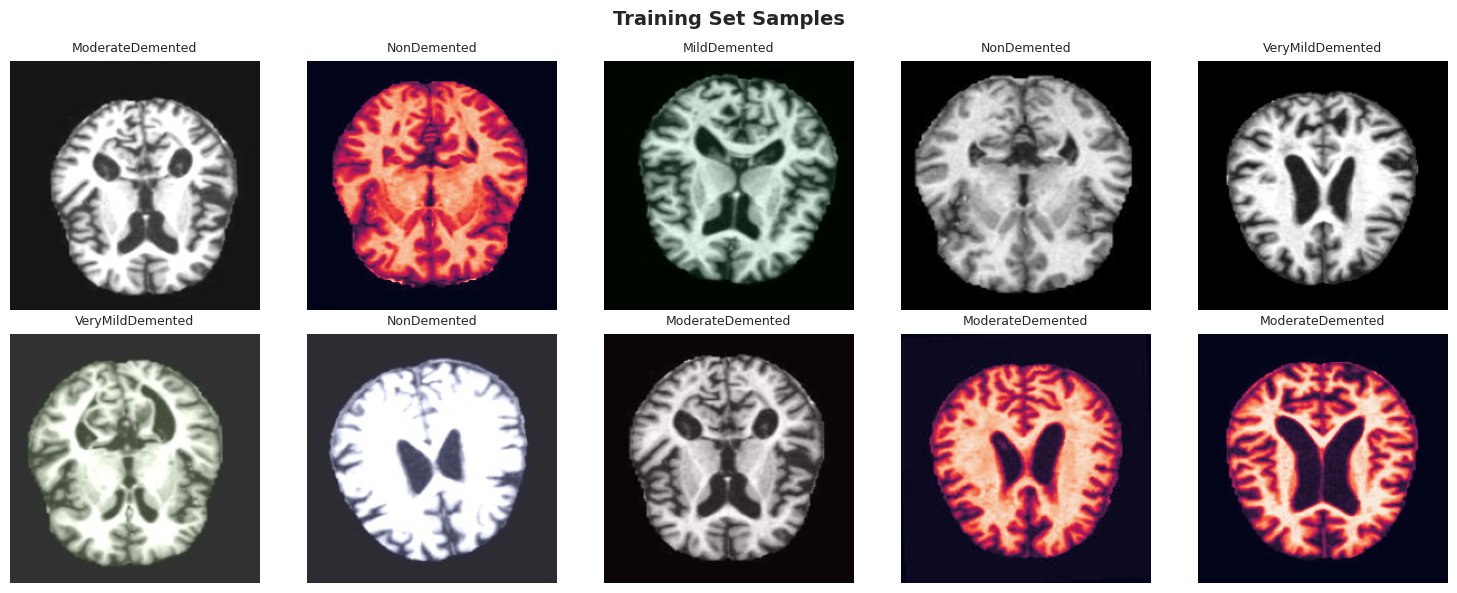

In [8]:
def show_sample_images(paths, labels, n=10, title='Sample Images'):
    indices = random.sample(range(len(paths)), min(n, len(paths)))
    cols = 5
    rows = math.ceil(len(indices) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
    axes = axes.ravel()
    for i, idx in enumerate(indices):
        img = Image.open(paths[idx]).resize((IMAGE_SIZE, IMAGE_SIZE))
        axes[i].imshow(img)
        axes[i].set_title(labels[idx], fontsize=9)
        axes[i].axis('off')
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    plt.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

show_sample_images(train_paths, train_labels, n=10, title='Training Set Samples')

In [9]:
# ---- Label encoding --------------------------------------------------------
LABEL_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

def encode_labels(labels):
    return np.array([LABEL_TO_IDX[l] for l in labels])


# ---- Image loading helpers -------------------------------------------------
def augment_image(img_array):
    """Apply brightness + contrast jitter and optional horizontal flip."""
    image = Image.fromarray(np.uint8(img_array * 255))
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))
    if random.random() > 0.5:
        image = image.transpose(Image.FLIP_LEFT_RIGHT)
    return np.array(image) / 255.0


def load_images(paths, augment=False):
    images = []
    for path in paths:
        img = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        arr = img_to_array(img) / 255.0
        if augment:
            arr = augment_image(arr)
        images.append(arr)
    return np.array(images)


# ---- Batch generators ------------------------------------------------------
def data_generator(paths, labels, batch_size=BATCH_SIZE, augment=True, epochs=1):
    """Yields (images, encoded_labels) batches, one epoch at a time."""
    for _ in range(epochs):
        paths, labels = shuffle(paths, labels)
        for i in range(0, len(paths), batch_size):
            bp = paths[i:i + batch_size]
            bl = labels[i:i + batch_size]
            yield load_images(bp, augment=augment), encode_labels(bl)


def eval_generator(paths, labels, batch_size=BATCH_SIZE):
    """Non-augmented generator for validation / test inference."""
    for i in range(0, len(paths), batch_size):
        bp = paths[i:i + batch_size]
        bl = labels[i:i + batch_size]
        yield load_images(bp, augment=False), encode_labels(bl)


print('Data generators ready.')

Data generators ready.


In [10]:
#============================================================
#Xception PURE PRETRAINED BASELINE
#============================================================

base_model=Xception(
input_shape=(IMAGE_SIZE,IMAGE_SIZE,3),
include_top=False,
weights='imagenet'
)

#FREEZE ALL BASE LAYERS
for layer in base_model.layers:
    layer.trainable=False

trainable_count=sum(
1 for l in base_model.layers
if l.trainable
)

print(
f'Trainable base layers: {trainable_count} / {len(base_model.layers)}'
)

#BUILD CLASSIFICATION HEAD
model=Sequential([
Input(shape=(IMAGE_SIZE,IMAGE_SIZE,3)),
base_model,
GlobalAveragePooling2D(),
Dropout(0.4),
Dense(256,activation='relu'),
Dropout(0.3),
Dense(NUM_CLASSES,activation='softmax')
],name='Xception_Baseline')

#COMPILE MODEL
model.compile(
optimizer=Adam(
learning_rate=LEARNING_RATE
),
loss='sparse_categorical_crossentropy',
metrics=['sparse_categorical_accuracy']
)

model.summary()

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Trainable base layers: 0 / 132


Model: "Xception_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xception (Functional)           │ (None, 7, 7, 2048)     │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,387,052 (81.59 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 20,861,480 (79.58 MB)

## Step 8: Train the Model

In [11]:
steps_per_epoch = math.ceil(len(train_paths) / BATCH_SIZE)
val_steps       = math.ceil(len(val_paths)   / BATCH_SIZE)

callbacks = [
    EarlyStopping(
        monitor='val_sparse_categorical_accuracy',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        MODEL_SAVE_PATH,
        monitor='val_sparse_categorical_accuracy',
        save_best_only=True,
        verbose=1
    )
]

history = model.fit(
    data_generator(train_paths, train_labels, augment=True, epochs=EPOCHS),
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_data=eval_generator(val_paths, val_labels),
    validation_steps=val_steps,
    callbacks=callbacks,
    verbose=1
)

print('\nTraining complete!')

Epoch 1/20
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - loss: 1.1091 - sparse_categorical_accuracy: 0.4993
Epoch 1: val_sparse_categorical_accuracy improved from None to 0.64286, saving model to Xception_Baseline model.keras

Epoch 1: finished saving model to Xception_Baseline model.keras
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 359s 79ms/step - loss: 1.0007 - sparse_categorical_accuracy: 0.5507 - val_loss: 0.8015 - val_sparse_categorical_accuracy: 0.6429 - learning_rate: 1.0000e-04
Epoch 2/20
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - loss: 0.8636 - sparse_categorical_accuracy: 0.6145
Epoch 2: val_sparse_categorical_accuracy improved from 0.64286 to 0.75000, saving model to Xception_Baseline model.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: finished saving model to Xception_Baseline model.keras
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 296s 70ms/step - loss: 0.8497 - sparse_categorical_accuracy: 0.6188 - val_loss: 0.6106 - val_sparse_categorical_accuracy: 0.7500 - learning_rate: 1.0000e-04
Epoch 3/20
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - loss: 0.8032 - sparse_categorical_accuracy: 0.6409
Epoch 3: val_sparse_categorical_accuracy did not improve from 0.75000
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 296s 70ms/step - loss: 0.7979 - sparse_categorical_accuracy: 0.6419 - val_loss: 0.5531 - val_sparse_categorical_accuracy: 0.7188 - learning_rate: 1.0000e-04
Epoch 4/20
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - loss: 0.7766 - sparse_categorical_accuracy: 0.6517
Epoch 4: val_sparse_categorical_accuracy did not improve from 0.75000
4200/4200 ━━━━━━━━━━━━━━━━━━━━ 293s 70ms/step - loss: 0.7645 - sparse_categorical_accuracy: 0.6588 - val_loss: 0.5382 - val_sparse_categorical_accuracy: 0.7500 - learning_rate: 1.0000e-04
Epoch 5/20
4200

## Step 9: Training History Plots

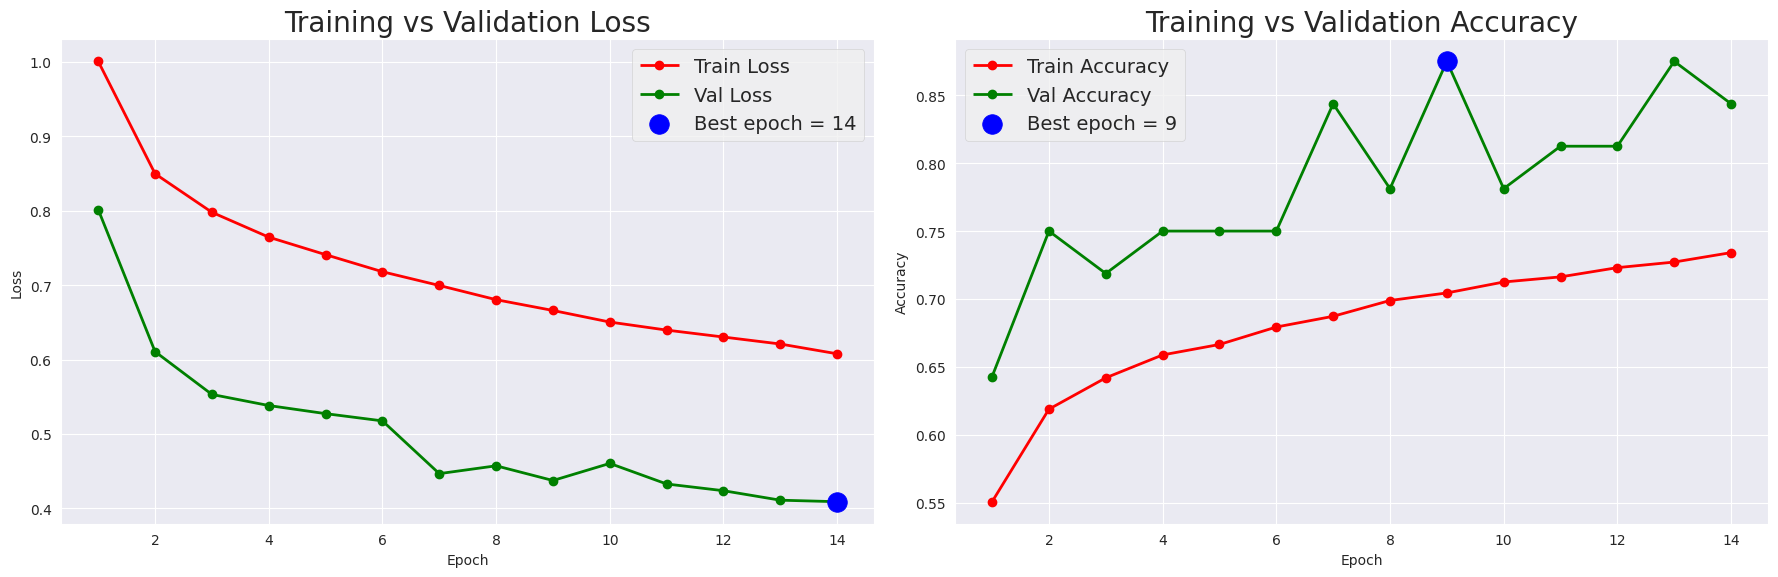

Best val accuracy: 0.8750 at epoch 9
Best val loss    : 0.4090 at epoch 14


In [12]:
def plot_training_history(history):
    acc_key  = 'sparse_categorical_accuracy'
    vacc_key = 'val_sparse_categorical_accuracy'

    tacc  = history.history[acc_key]
    vacc  = history.history[vacc_key]
    tloss = history.history['loss']
    vloss = history.history['val_loss']
    epochs_range = range(1, len(tacc) + 1)

    best_val_loss_ep  = int(np.argmin(vloss))  + 1
    best_val_acc_ep   = int(np.argmax(vacc))   + 1

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    plt.style.use('fivethirtyeight')

    # Loss
    axes[0].plot(epochs_range, tloss, 'r-o', label='Train Loss', linewidth=2)
    axes[0].plot(epochs_range, vloss, 'g-o', label='Val Loss',   linewidth=2)
    axes[0].scatter(best_val_loss_ep, vloss[best_val_loss_ep - 1],
                    s=200, c='blue', zorder=5, label=f'Best epoch = {best_val_loss_ep}')
    axes[0].set_title('Training vs Validation Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()

    # Accuracy
    axes[1].plot(epochs_range, tacc, 'r-o', label='Train Accuracy', linewidth=2)
    axes[1].plot(epochs_range, vacc, 'g-o', label='Val Accuracy',   linewidth=2)
    axes[1].scatter(best_val_acc_ep, vacc[best_val_acc_ep - 1],
                    s=200, c='blue', zorder=5, label=f'Best epoch = {best_val_acc_ep}')
    axes[1].set_title('Training vs Validation Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()

    plt.tight_layout()
    plt.show()
    print(f'Best val accuracy: {max(vacc):.4f} at epoch {best_val_acc_ep}')
    print(f'Best val loss    : {min(vloss):.4f} at epoch {best_val_loss_ep}')

plot_training_history(history)

## Step 10: Evaluate on Test Set

In [13]:
# Collect all predictions in batches
all_preds, all_true = [], []
for imgs, lbls in eval_generator(test_paths, test_labels):
    preds = model.predict(imgs, verbose=0)
    all_preds.append(preds)
    all_true.extend(lbls)

all_preds      = np.vstack(all_preds)          # shape: (N, num_classes)
pred_classes   = np.argmax(all_preds, axis=1)  # shape: (N,)
true_classes   = np.array(all_true)            # shape: (N,)

print(f'Test samples evaluated: {len(true_classes)}')

# Overall accuracy
test_acc = np.mean(pred_classes == true_classes)
print(f'Test Accuracy: {test_acc:.4f} ({test_acc * 100:.2f}%)')

Test samples evaluated: 8400
Test Accuracy: 0.7690 (76.90%)


## Step 11: Classification Report

In [14]:
print('Classification Report')
print('=' * 60)
print(classification_report(
    true_classes,
    pred_classes,
    target_names=CLASS_NAMES
))

Classification Report
                  precision    recall  f1-score   support

    MildDemented       0.72      0.82      0.77      1989
ModerateDemented       0.96      1.00      0.98      2003
     NonDemented       0.74      0.69      0.72      2305
VeryMildDemented       0.64      0.59      0.61      2103

        accuracy                           0.77      8400
       macro avg       0.77      0.77      0.77      8400
    weighted avg       0.77      0.77      0.77      8400



## Step 12: Confusion Matrix

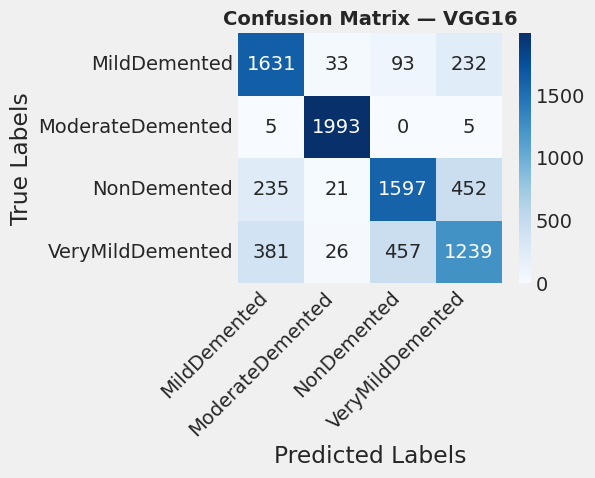

In [15]:
cm = confusion_matrix(true_classes, pred_classes)

plt.figure(figsize=(max(6, NUM_CLASSES * 1.5), max(5, NUM_CLASSES * 1.2)))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title('Confusion Matrix — VGG16', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Step 13: ROC-AUC Curve (Per Class)

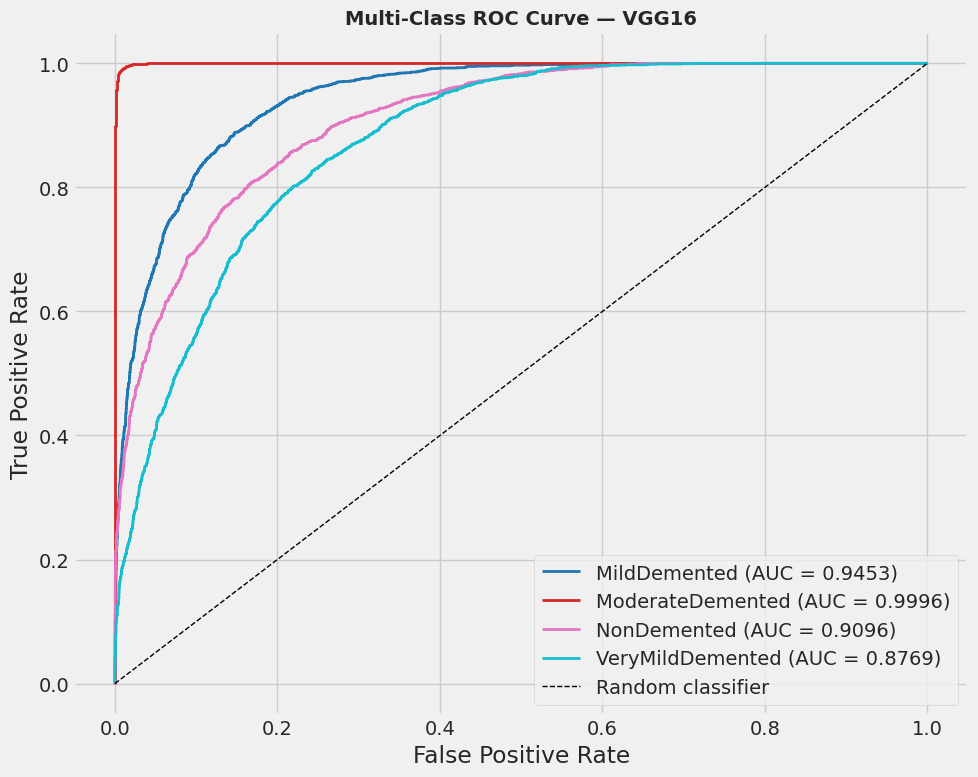


AUC Scores per class:
  MildDemented                  : 0.9453
  ModerateDemented              : 0.9996
  NonDemented                   : 0.9096
  VeryMildDemented              : 0.8769

Mean AUC: 0.9329


In [16]:
# Binarise true labels for one-vs-rest ROC
true_bin = label_binarize(true_classes, classes=np.arange(NUM_CLASSES))

fpr, tpr, roc_auc = {}, {}, {}
for i in range(NUM_CLASSES):
    fpr[i], tpr[i], _ = roc_curve(true_bin[:, i], all_preds[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(10, 8))
colors = plt.cm.tab10(np.linspace(0, 1, NUM_CLASSES))
for i, color in zip(range(NUM_CLASSES), colors):
    plt.plot(
        fpr[i], tpr[i],
        color=color,
        linewidth=2,
        label=f'{CLASS_NAMES[i]} (AUC = {roc_auc[i]:.4f})'
    )
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random classifier')
plt.title('Multi-Class ROC Curve — VGG16', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

print('\nAUC Scores per class:')
for i in range(NUM_CLASSES):
    print(f'  {CLASS_NAMES[i]:30s}: {roc_auc[i]:.4f}')
mean_auc = np.mean(list(roc_auc.values()))
print(f'\nMean AUC: {mean_auc:.4f}')

## Step 14: Visualise Predictions on Test Images

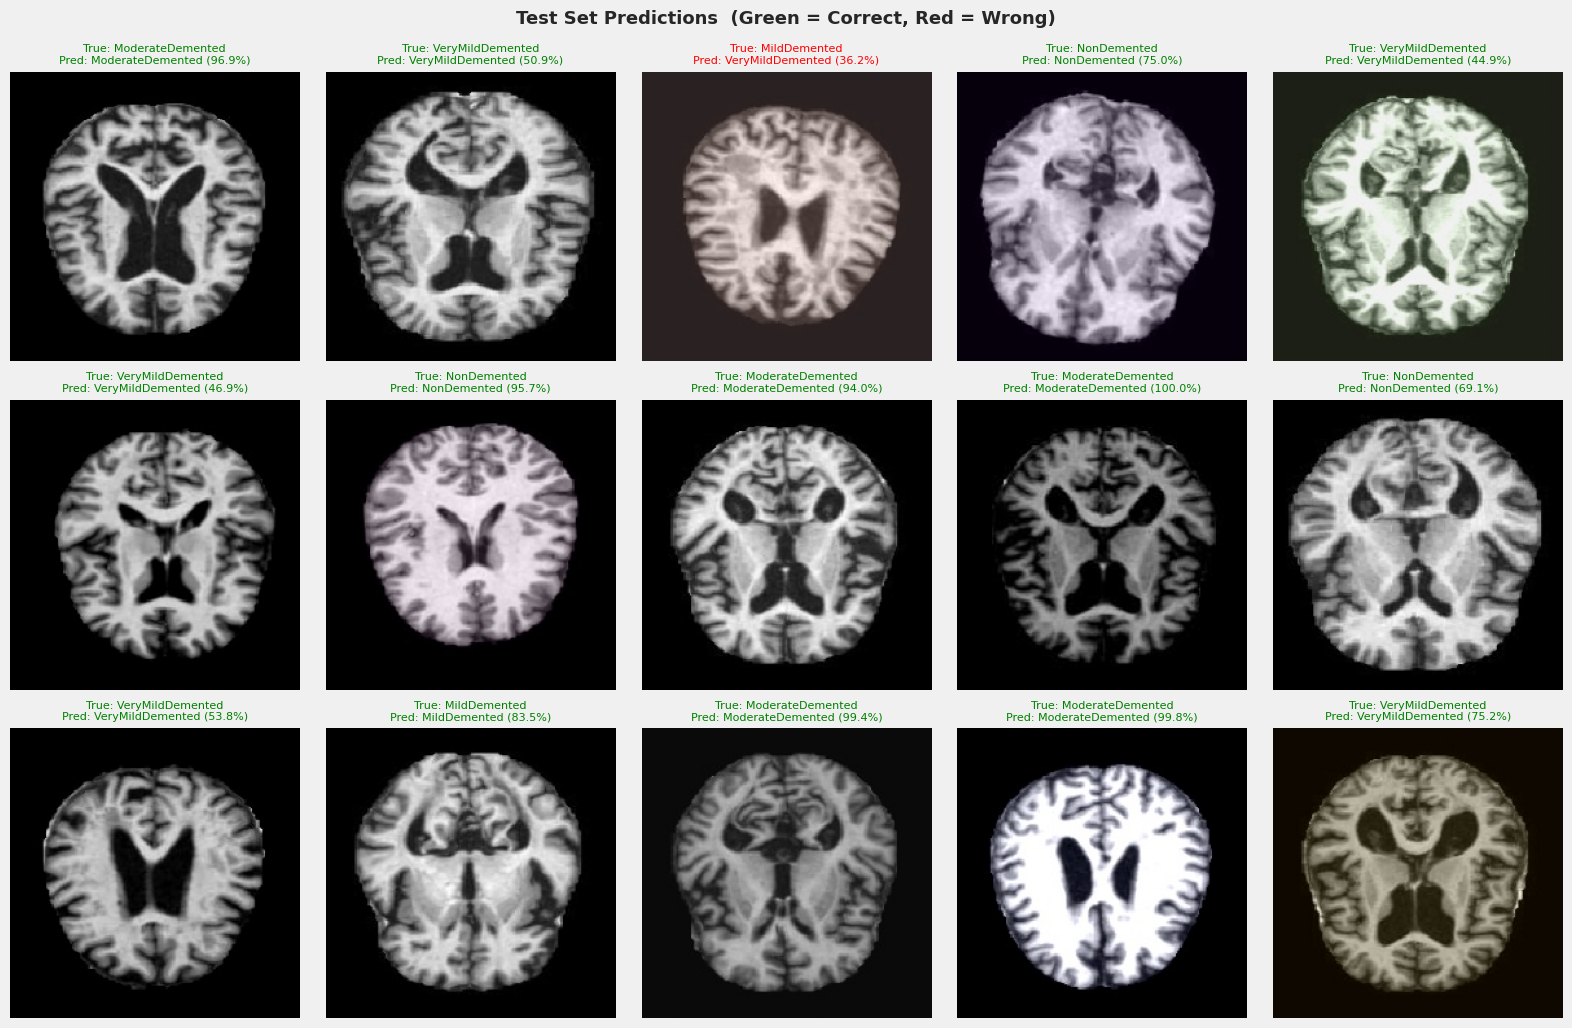

In [17]:
def show_predictions(paths, labels, n=15):
    indices = random.sample(range(len(paths)), min(n, len(paths)))
    cols = 5
    rows = math.ceil(len(indices) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 3.5))
    axes = axes.ravel()

    for ax_i, idx in enumerate(indices):
        img_arr = load_images([paths[idx]], augment=False)[0]
        pred    = model.predict(np.expand_dims(img_arr, 0), verbose=0)
        pred_cls  = CLASS_NAMES[np.argmax(pred)]
        true_cls  = labels[idx]
        confidence = np.max(pred) * 100

        axes[ax_i].imshow(img_arr)
        axes[ax_i].axis('off')
        color = 'green' if pred_cls == true_cls else 'red'
        axes[ax_i].set_title(
            f'True: {true_cls}\nPred: {pred_cls} ({confidence:.1f}%)',
            color=color, fontsize=8
        )

    for j in range(ax_i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle('Test Set Predictions  (Green = Correct, Red = Wrong)',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

show_predictions(test_paths, test_labels, n=15)

## Step 15: Single Image Prediction

Actual Class    : NonDemented
Predicted Class : VeryMildDemented
Confidence      : 50.87%


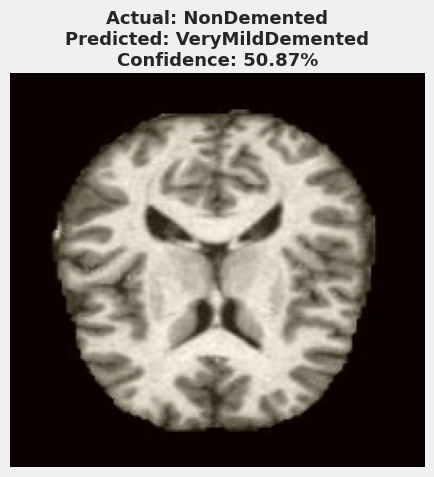


Prediction Probabilities:
MildDemented        : 10.48%
ModerateDemented    : 0.00%
NonDemented         : 38.66%
VeryMildDemented    : 50.87%


In [18]:
# -----------------------------
# Single Test Image Prediction
# -----------------------------

idx = np.random.randint(len(test_paths))

img_path = test_paths[idx]

img = load_img(
    img_path,
    target_size=(IMAGE_SIZE, IMAGE_SIZE)
)

arr = img_to_array(img) / 255.0

arr = np.expand_dims(
    arr,
    axis=0
)

preds = model.predict(
    arr,
    verbose=0
)

pred_idx = np.argmax(preds)

pred_class = CLASS_NAMES[pred_idx]

confidence = np.max(preds) * 100

print(f'Actual Class    : {test_labels[idx]}')
print(f'Predicted Class : {pred_class}')
print(f'Confidence      : {confidence:.2f}%')

plt.figure(figsize=(5, 5))

plt.imshow(load_img(img_path))

plt.axis('off')

plt.title(
    f'Actual: {test_labels[idx]}\n'
    f'Predicted: {pred_class}\n'
    f'Confidence: {confidence:.2f}%',
    fontsize=13,
    fontweight='bold'
)

plt.tight_layout()

plt.show()

print('\nPrediction Probabilities:')

for cls, prob in zip(CLASS_NAMES, preds[0]):
    print(f'{cls:20s}: {prob * 100:.2f}%')

## Step 16: Save & Reload Model

In [19]:
# Best model was already saved by ModelCheckpoint callback.
# Reload it here to confirm everything works.
model = load_model(MODEL_SAVE_PATH)
print(f'Model loaded from: {MODEL_SAVE_PATH}')
print(f'Model input shape : {model.input_shape}')
print(f'Model output shape: {model.output_shape}')
print(f'Total parameters  : {model.count_params():,}')

Model loaded from: Xception_Baseline model.keras
Model input shape : (None, 224, 224, 3)
Model output shape: (None, 4)
Total parameters  : 21,387,052


In [20]:
model.save(MODEL_SAVE_PATH)
print(f'Current model state saved to: {MODEL_SAVE_PATH}')

Current model state saved to: Xception_Baseline model.keras
